<a href="https://colab.research.google.com/github/vaanchhitbaranwal-ux/Vaanchhit/blob/main/Banking_%26_Fraud_Transaction_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Dataset loaded successfully ===
Shape of dataset: 5000 rows, 7 columns

--- First 5 rows ---


,transaction_id,customer_id,age,transaction_amount,card_type,merchant_category,is_fraud
0,TX_000000,C_1102,31,77.08,Credit,Groceries,0
1,TX_000001,C_1435,73,21.31,Credit,Gas_Station,0
2,TX_000002,C_1860,79,127.02,Credit,Online Retail,0
3,TX_000003,C_1270,72,31.68,Credit,Entertainment,0
4,TX_000004,C_1106,44,38.01,Debit,Entertainment,0



--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   transaction_id      5000 non-null   object 
 1   customer_id         5000 non-null   object 
 2   age                 5000 non-null   int64  
 3   transaction_amount  5000 non-null   float64
 4   card_type           5000 non-null   object 
 5   merchant_category   5000 non-null   object 
 6   is_fraud            5000 non-null   int64  
dtypes: float64(1), int64(2), object(4)
memory usage: 273.6+ KB
None

--- Summary Statistics (Numerical Features) ---


,age,transaction_amount,is_fraud
count,5000.000000,5000.000000,5000.000000
mean,48.833400,100.359314,0.014800
std,17.895242,101.405847,0.120764
min,18.000000,0.020000,0.000000
25%,34.000000,29.655000,0.000000
50%,49.000000,70.030000,0.000000
75%,65.000000,137.950000,0.000000
max,79.000000,879.990000,1.000000



--- Missing Values ---
transaction_id        0
customer_id           0
age                   0
transaction_amount    0
card_type             0
merchant_category     0
is_fraud              0
dtype: int64

--- Target Variable Distribution ---
Legitimate Transactions (0): 4926 (98.52%)
Fraudulent Transactions (1): 74 (1.48%)


/tmp/ipykernel_474/2625021039.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='is_fraud', data=df, palette='Set1')


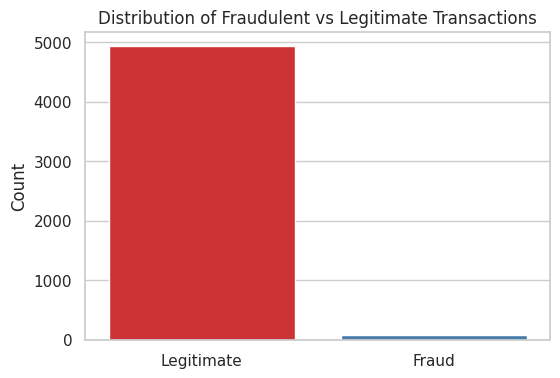

/tmp/ipykernel_474/2625021039.py:79: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='is_fraud', y='transaction_amount', data=df, palette='Set1')


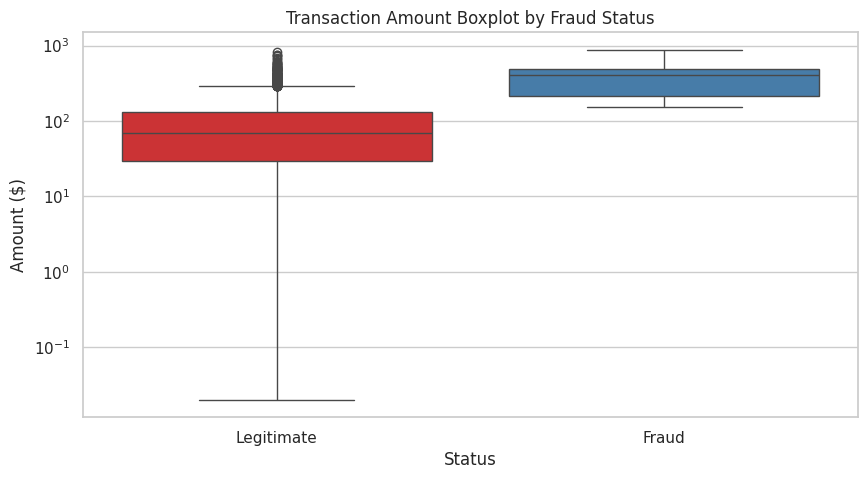

/tmp/ipykernel_474/2625021039.py:89: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='merchant_category', y='is_fraud', data=df, ci=None, palette='viridis')
/tmp/ipykernel_474/2625021039.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='merchant_category', y='is_fraud', data=df, ci=None, palette='viridis')


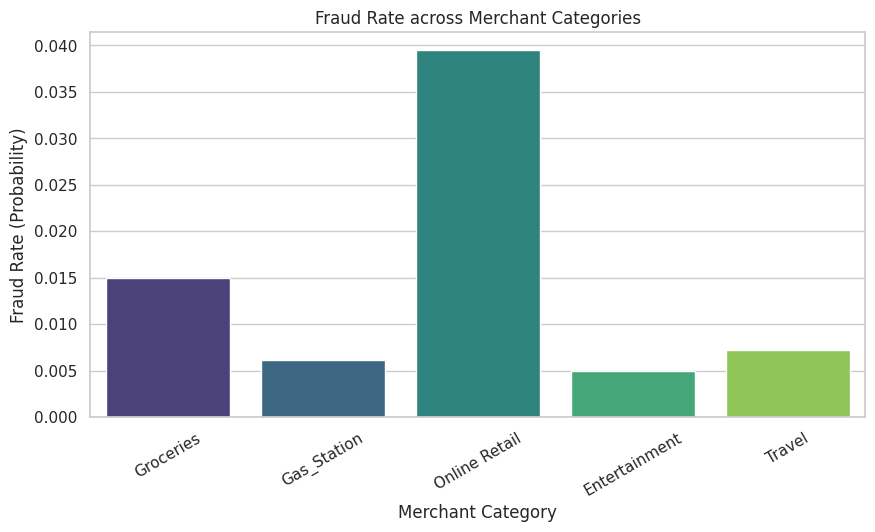

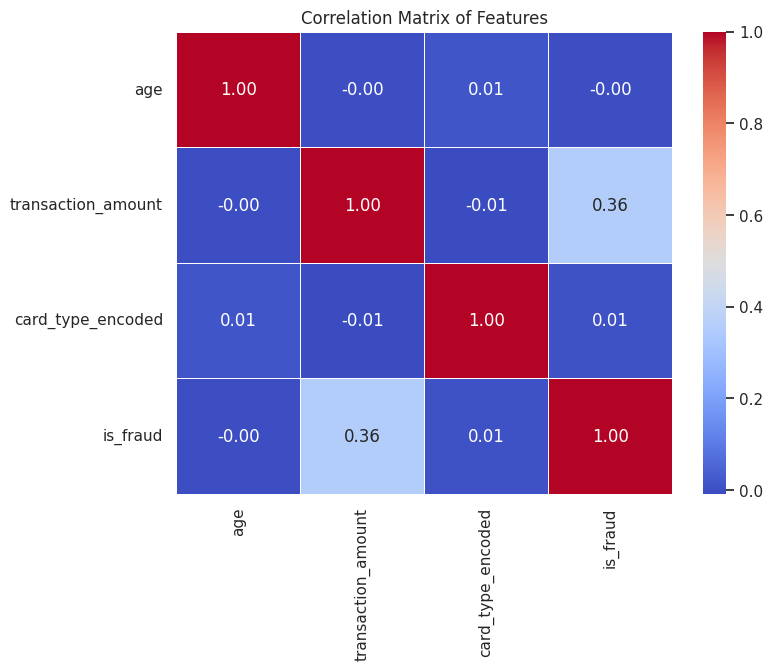

In [1]:
# Banking & Fraud Exploratory Data Analysis (EDA)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization styles
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# =====================================================================
# 1. GENERATE SYNTHETIC BANKING & FRAUD DATA
# (If you have a CSV, replace this section with: df = pd.read_csv('your_file.csv'))
# =====================================================================
np.random.seed(42)
n_samples = 5000

data = {
    'transaction_id': [f'TX_{i:06d}' for i in range(n_samples)],
    'customer_id': [f'C_{np.random.randint(1000, 2000)}' for _ in range(n_samples)],
    'age': np.random.randint(18, 80, size=n_samples),
    'transaction_amount': np.round(np.random.exponential(scale=100, size=n_samples), 2),
    'card_type': np.random.choice(['Debit', 'Credit', 'Prepaid'], size=n_samples, p=[0.5, 0.4, 0.1]),
    'merchant_category': np.random.choice(['Groceries', 'Entertainment', 'Travel', 'Online Retail', 'Gas_Station'], size=n_samples),
    'is_fraud': np.zeros(n_samples, dtype=int)
}

df = pd.DataFrame(data)

# Inject fraud rules to make EDA interesting:
# Rule 1: High transaction amounts are more likely to be fraud
fraud_indices = df[df['transaction_amount'] > 400].sample(frac=0.4, random_state=42).index
df.loc[fraud_indices, 'is_fraud'] = 1

# Rule 2: Online retail has higher fraud rate
online_indices = df[(df['merchant_category'] == 'Online Retail') & (df['transaction_amount'] > 150)].sample(frac=0.15, random_state=42).index
df.loc[online_indices, 'is_fraud'] = 1

print("=== Dataset loaded successfully ===")
print(f"Shape of dataset: {df.shape[0]} rows, {df.shape[1]} columns\n")

# =====================================================================
# 2. DATA INSPECTION
# =====================================================================
print("--- First 5 rows ---")
display(df.head())

print("\n--- Dataset Info ---")
print(df.info())

print("\n--- Summary Statistics (Numerical Features) ---")
display(df.describe())

print("\n--- Missing Values ---")
print(df.isnull().sum())

# =====================================================================
# 3. EXPLORATORY DATA ANALYSIS (EDA)
# =====================================================================

# A. Target Variable Distribution (Fraud vs Legitimate)
print("\n--- Target Variable Distribution ---")
fraud_counts = df['is_fraud'].value_counts()
fraud_pct = df['is_fraud'].value_counts(normalize=True) * 100
print(f"Legitimate Transactions (0): {fraud_counts[0]} ({fraud_pct[0]:.2f}%)")
print(f"Fraudulent Transactions (1): {fraud_counts[1]} ({fraud_pct[1]:.2f}%)")

plt.figure(figsize=(6, 4))
sns.countplot(x='is_fraud', data=df, palette='Set1')
plt.title('Distribution of Fraudulent vs Legitimate Transactions')
plt.xticks([0, 1], ['Legitimate', 'Fraud'])
plt.xlabel('')
plt.ylabel('Count')
plt.show()

# B. Transaction Amount Distribution by Fraud Status
plt.figure(figsize=(10, 5))
sns.boxplot(x='is_fraud', y='transaction_amount', data=df, palette='Set1')
plt.title('Transaction Amount Boxplot by Fraud Status')
plt.xticks([0, 1], ['Legitimate', 'Fraud'])
plt.xlabel('Status')
plt.ylabel('Amount ($)')
plt.yscale('log') # Log scale helps handle high amount outliers
plt.show()

# C. Fraud Rate by Merchant Category
plt.figure(figsize=(10, 5))
sns.barplot(x='merchant_category', y='is_fraud', data=df, ci=None, palette='viridis')
plt.title('Fraud Rate across Merchant Categories')
plt.ylabel('Fraud Rate (Probability)')
plt.xlabel('Merchant Category')
plt.xticks(rotation=30)
plt.show()

# D. Correlation Heatmap
plt.figure(figsize=(8, 6))
# We encode categorical card_type to include it in correlations
df_encoded = df.copy()
df_encoded['card_type_encoded'] = df_encoded['card_type'].astype('category').cat.codes
corr_matrix = df_encoded[['age', 'transaction_amount', 'card_type_encoded', 'is_fraud']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Features')
plt.show()

In [2]:
from google.colab import drive
# This will prompt for authorization
drive.mount('/content/drive')

# Template to load your dataset from Google Drive once mounted:
# replace 'path/to/your/banking_data.csv' with your actual file path
# path_to_file = '/content/drive/MyDrive/path/to/your/banking_data.csv'
# df = pd.read_csv(path_to_file)

Mounted at /content/drive


In [6]:
import pandas as pd
import os

# Update this path to point to your actual CSV file inside Google Drive
# e.g., '/content/drive/MyDrive/MyFolder/banking_data.csv'
gdrive_file_path = '/content/drive/MyDrive/path/to/your/banking_data.csv'

if os.path.exists(gdrive_file_path):
    df = pd.read_csv(gdrive_file_path)
    print("=== Dataset loaded successfully from Google Drive ===")
    print(f"Shape of dataset: {df.shape[0]} rows, {df.shape[1]} columns")
    display(df.head())
else:
    print(f"[ERROR] File not found at: {gdrive_file_path}")
    print("Please update the 'gdrive_file_path' variable with your actual Google Drive CSV path.")

[ERROR] File not found at: /content/drive/MyDrive/path/to/your/banking_data.csv
Please update the 'gdrive_file_path' variable with your actual Google Drive CSV path.


=== Model Evaluation ===

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       985
           1       0.67      0.13      0.22        15

    accuracy                           0.99      1000
   macro avg       0.83      0.57      0.61      1000
weighted avg       0.98      0.99      0.98      1000

ROC-AUC Score: 0.9488



/tmp/ipykernel_474/2438824454.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='mako')


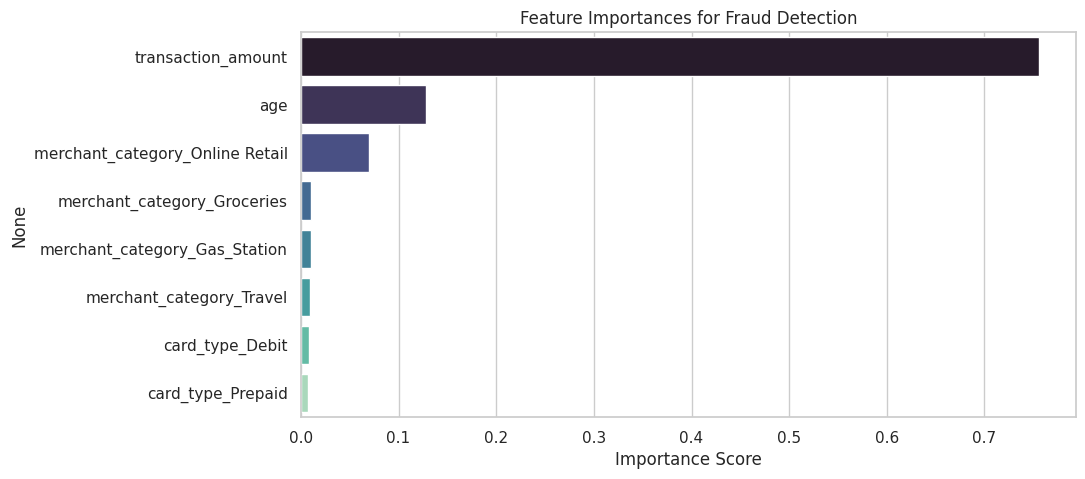

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# =====================================================================
# 1. PREPROCESSING & FEATURE SELECTION
# =====================================================================
# Drop unique IDs that don't help prediction
features = df.drop(columns=['transaction_id', 'customer_id', 'is_fraud'])
target = df['is_fraud']

# One-Hot Encode categorical variables
features_encoded = pd.get_dummies(features, columns=['card_type', 'merchant_category'], drop_first=True)

# =====================================================================
# 2. STRATIFIED TRAIN-TEST SPLIT
# =====================================================================
X_train, X_test, y_train, y_test = train_test_split(
    features_encoded,
    target,
    test_size=0.2,
    random_state=42,
    stratify=target
)

# =====================================================================
# 3. MODEL TRAINING (Handling Class Imbalance with class_weight='balanced')
# =====================================================================
model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

# =====================================================================
# 4. EVALUATION
# =====================================================================
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

print("=== Model Evaluation ===\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}\n")

# Plot Feature Importances
importances = pd.Series(model.feature_importances_, index=features_encoded.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=importances.values, y=importances.index, palette='mako')
plt.title('Feature Importances for Fraud Detection')
plt.xlabel('Importance Score')
plt.show()

=== Logistic Regression Evaluation ===

              precision    recall  f1-score   support

           0       1.00      0.95      0.97       985
           1       0.22      1.00      0.37        15

    accuracy                           0.95      1000
   macro avg       0.61      0.97      0.67      1000
weighted avg       0.99      0.95      0.96      1000

ROC-AUC Score: 0.9817



/tmp/ipykernel_474/3969409787.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=coefficients.values, y=coefficients.index, palette='coolwarm')


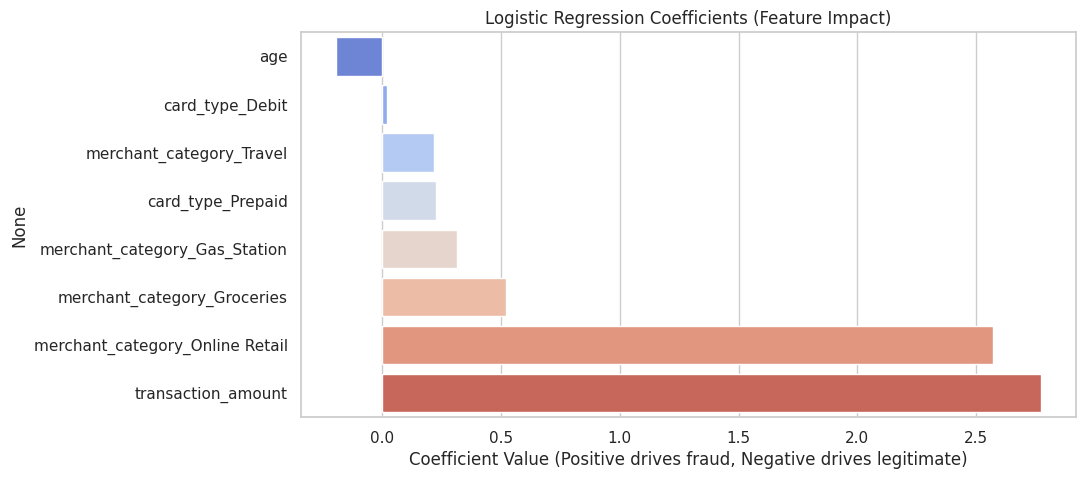

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# =====================================================================
# 1. SCALE FEATURES (Important for Logistic Regression)
# =====================================================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =====================================================================
# 2. MODEL TRAINING (With balanced class weight to handle imbalance)
# =====================================================================
lr_model = LogisticRegression(class_weight='balanced', random_state=42)
lr_model.fit(X_train_scaled, y_train)

# =====================================================================
# 3. EVALUATION
# =====================================================================
y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_proba_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

print("=== Logistic Regression Evaluation ===\n")
print(classification_report(y_test, y_pred_lr))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_lr):.4f}\n")

# Plot Coefficients (Feature Importance)
coefficients = pd.Series(lr_model.coef_[0], index=features_encoded.columns).sort_values()
plt.figure(figsize=(10, 5))
sns.barplot(x=coefficients.values, y=coefficients.index, palette='coolwarm')
plt.title('Logistic Regression Coefficients (Feature Impact)')
plt.xlabel('Coefficient Value (Positive drives fraud, Negative drives legitimate)')
plt.show()

=== Decision Tree Evaluation ===

              precision    recall  f1-score   support

           0       1.00      0.96      0.98       985
           1       0.27      0.93      0.42        15

    accuracy                           0.96      1000
   macro avg       0.63      0.95      0.70      1000
weighted avg       0.99      0.96      0.97      1000

ROC-AUC Score: 0.9492



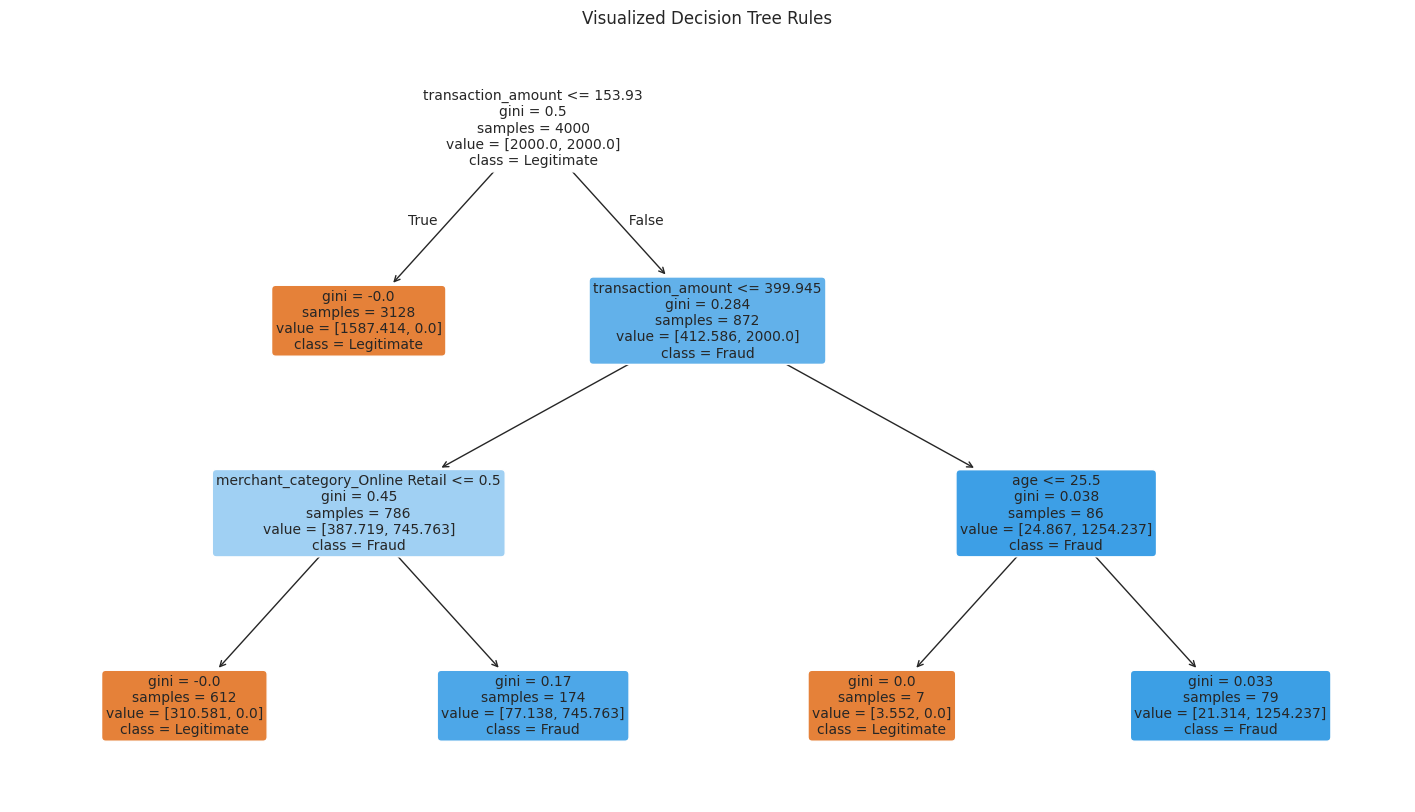

In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# =====================================================================
# 1. MODEL TRAINING (Setting max_depth=3 for simplicity and visualization)
# =====================================================================
dt_model = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=42)
dt_model.fit(X_train, y_train)

# =====================================================================
# 2. EVALUATION
# =====================================================================
y_pred_dt = dt_model.predict(X_test)
y_pred_proba_dt = dt_model.predict_proba(X_test)[:, 1]

print("=== Decision Tree Evaluation ===\n")
print(classification_report(y_test, y_pred_dt))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_dt):.4f}\n")

# =====================================================================
# 3. VISUALIZE THE DECISION TREE
# =====================================================================
plt.figure(figsize=(18, 10))
plot_tree(
    dt_model,
    feature_names=features_encoded.columns.tolist(),
    class_names=['Legitimate', 'Fraud'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Visualized Decision Tree Rules")
plt.show()

### Step-by-Step Training of a Simple Machine Learning Model
We will use a **Decision Tree Classifier** from `scikit-learn` to classify transactions. This model learns simple decision rules inferred from the data features.

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Initialize the model with balanced weights to handle class imbalance
simple_model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)

# 2. Fit (train) the model on our training data
simple_model.fit(X_train, y_train)

# 3. Predict the labels on the test dataset
y_predictions = simple_model.predict(X_test)

# 4. Measure model performance
accuracy = accuracy_score(y_test, y_predictions)
print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_predictions))

Model Accuracy: 96.70%

Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.97      0.98       985
           1       0.30      0.93      0.46        15

    accuracy                           0.97      1000
   macro avg       0.65      0.95      0.72      1000
weighted avg       0.99      0.97      0.98      1000



### Alternative Model Example: k-Nearest Neighbors (k-NN)
k-NN classifies an unseen data point by looking at the labeled points closest to it. Because it is distance-based, we use the scaled feature sets (`X_train_scaled`, `X_test_scaled`) to ensure features like `age` and `transaction_amount` are treated equally.

In [8]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Initialize the k-NN model (e.g., looking at the 5 nearest neighbors)
knn_model = KNeighborsClassifier(n_neighbors=5)

# 2. Fit the model on our scaled training data
knn_model.fit(X_train_scaled, y_train)

# 3. Predict classifications on the scaled test dataset
y_pred_knn = knn_model.predict(X_test_scaled)

# 4. Print overall performance metrics
knn_accuracy = accuracy_score(y_test, y_pred_knn)
print(f"k-NN Model Accuracy: {knn_accuracy * 100:.2f}%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_knn))

k-NN Model Accuracy: 98.40%

Classification Report:

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       985
           1       0.00      0.00      0.00        15

    accuracy                           0.98      1000
   macro avg       0.49      0.50      0.50      1000
weighted avg       0.97      0.98      0.98      1000



### Support Vector Machine (SVM) Classifier Example

Support Vector Classifiers (SVC) find a boundary that maximizes the distance between the closest points of different classes (support vectors). We use `class_weight='balanced'` to prevent the boundary from ignoring the small fraudulent class.

In [10]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score

# 1. Initialize the Support Vector Classifier with balanced class weights
svm_model = SVC(kernel='linear', class_weight='balanced', probability=True, random_state=42)

# 2. Train the model on scaled training data
svm_model.fit(X_train_scaled, y_train)

# 3. Predict the test dataset
y_pred_svm = svm_model.predict(X_test_scaled)

# 4. Print metrics
svm_accuracy = accuracy_score(y_test, y_pred_svm)
print(f"SVM Model Accuracy: {svm_accuracy * 100:.2f}%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_svm))

SVM Model Accuracy: 94.40%

Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.94      0.97       985
           1       0.21      1.00      0.35        15

    accuracy                           0.94      1000
   macro avg       0.61      0.97      0.66      1000
weighted avg       0.99      0.94      0.96      1000



### Tuning SVM Hyperparameters for Precision

We will use `GridSearchCV` to search across different values of `C`, `kernel` types, and custom `class_weight` settings. We set `scoring='precision'` to ensure that cross-validation evaluates and picks the candidate model that yields the lowest false alarm rate.

In [19]:
import pandas as pd
from sklearn.metrics import roc_auc_score

# Create list of AUC results using current session variables
auc_results = []
for name, probs in model_probabilities.items():
    score = roc_auc_score(y_test, probs)
    auc_results.append({
        'Model': name,
        'ROC-AUC Score': round(score, 4)
    })

# Sort and display the table
auc_df_summary = pd.DataFrame(auc_results).sort_values(by='ROC-AUC Score', ascending=False).reset_index(drop=True)
display(auc_df_summary)

,Model,ROC-AUC Score
0,SVM (Linear),0.9823
1,Logistic Regression,0.9817
2,Optimized SVM,0.9672
3,Decision Tree (Max Depth 4),0.9514
4,Decision Tree (Max Depth 3),0.9492
5,Random Forest,0.9488
6,k-Nearest Neighbors,0.8554


In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score

# Define the hyperparameter grid
# We explore different values of C, different kernels, and custom class weight balances
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'class_weight': [
        'balanced',                         # Automatic balancing
        {0: 1, 1: 5},                       # Mildly biased towards class 1
        {0: 1, 1: 15}                       # Moderately biased towards class 1
    ]
}

# Initialize the Grid Search with the metric scoring set to 'precision'
# cv=3 is used here for speed on our synthetic dataset
grid_search = GridSearchCV(
    estimator=SVC(probability=True, random_state=42),
    param_grid=param_grid,
    scoring='precision',
    cv=3,
    n_jobs=-1,
    verbose=1
)

# Fit the grid search on the scaled training data
grid_search.fit(X_train_scaled, y_train)

# Print the best hyperparameters found
print(f"Best Hyperparameters for Precision: {grid_search.best_params_}")

# Evaluate the optimized model on the test set
best_svm = grid_search.best_estimator_
y_pred_opt_svm = best_svm.predict(X_test_scaled)

print(
    f"\n=== Optimized SVM Model Accuracy: {accuracy_score(y_test, y_pred_opt_svm) * 100:.2f}% ==="
)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_opt_svm))

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best Hyperparameters for Precision: {'C': 0.1, 'class_weight': {0: 1, 1: 5}, 'kernel': 'rbf'}

=== Optimized SVM Model Accuracy: 98.60% ===

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       985
           1       0.56      0.33      0.42        15

    accuracy                           0.99      1000
   macro avg       0.77      0.66      0.70      1000
weighted avg       0.98      0.99      0.98      1000



In [13]:
from sklearn.metrics import f1_score
import pandas as pd

# Create a dictionary of all prediction sets we have generated
predictions = {
    'Random Forest (Balanced)': y_pred,
    'Logistic Regression (Balanced)': y_pred_lr,
    'Decision Tree (Max Depth 3, Balanced)': y_pred_dt,
    'Decision Tree (Max Depth 4, Balanced)': y_predictions,
    'k-Nearest Neighbors (Default)': y_pred_knn,
    'SVM (Linear, Balanced)': y_pred_svm,
    'Optimized SVM (Tuned for Precision)': y_pred_opt_svm
}

# Calculate F1-scores
f1_records = []
for name, preds in predictions.items():
    f1_class_1 = f1_score(y_test, preds, pos_label=1)
    f1_macro = f1_score(y_test, preds, average='macro')
    f1_records.append({
        'Model': name,
        'Fraud F1-Score (Class 1)': round(f1_class_1, 4),
        'Macro F1-Score': round(f1_macro, 4)
    })

# Convert to DataFrame and sort by the correct key: 'Fraud F1-Score (Class 1)'
f1_df = pd.DataFrame(f1_records).sort_values(by='Fraud F1-Score (Class 1)', ascending=False).reset_index(drop=True)
display(f1_df)

,Model,Fraud F1-Score (Class 1),Macro F1-Score
0,"Decision Tree (Max Depth 4, Balanced)",0.4590,0.7210
1,"Decision Tree (Max Depth 3, Balanced)",0.4179,0.6989
2,Optimized SVM (Tuned for Precision),0.4167,0.7048
3,Logistic Regression (Balanced),0.3659,0.6694
4,"SVM (Linear, Balanced)",0.3488,0.6598
5,Random Forest (Balanced),0.2222,0.6076
6,k-Nearest Neighbors (Default),0.0000,0.4960


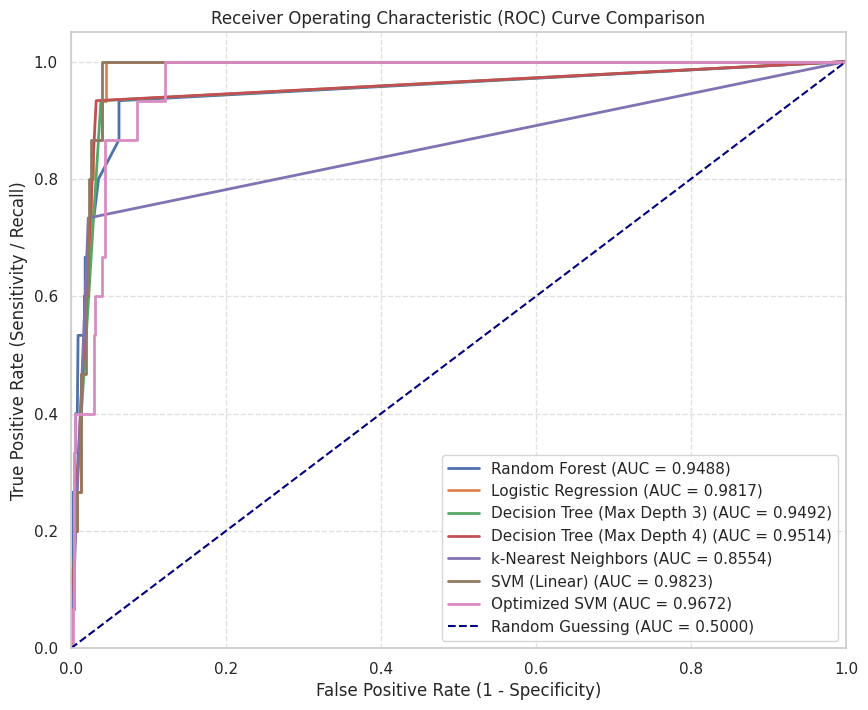

In [14]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Dictionary of models and their predicted probabilities
# Note: Some models (like k-NN or SVM) need probability predictions
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]
y_prob_opt_svm = best_svm.predict_proba(X_test_scaled)[:, 1]

model_probabilities = {
    'Random Forest': y_pred_proba,
    'Logistic Regression': y_pred_proba_lr,
    'Decision Tree (Max Depth 3)': y_pred_proba_dt,
    'Decision Tree (Max Depth 4)': simple_model.predict_proba(X_test)[:, 1],
    'k-Nearest Neighbors': y_prob_knn,
    'SVM (Linear)': y_prob_svm,
    'Optimized SVM': y_prob_opt_svm
}

plt.figure(figsize=(10, 8))

# Plot ROC curve for each model
for name, probs in model_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.4f})', lw=2)

# Plot the diagonal line representing random guessing
plt.plot([0, 1], [0, 1], color='navy', linestyle='--', label='Random Guessing (AUC = 0.5000)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve Comparison')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [15]:
from sklearn.metrics import roc_auc_score
import pandas as pd

# Calculate exact AUC scores for all trained models
auc_records = []
for name, probs in model_probabilities.items():
    auc_score = roc_auc_score(y_test, probs)
    auc_records.append({
        'Model': name,
        'ROC-AUC Score': round(auc_score, 4)
    })

# Convert to a DataFrame and sort by performance
auc_df = pd.DataFrame(auc_records).sort_values(by='ROC-AUC Score', ascending=False).reset_index(drop=True)
display(auc_df)

,Model,ROC-AUC Score
0,SVM (Linear),0.9823
1,Logistic Regression,0.9817
2,Optimized SVM,0.9672
3,Decision Tree (Max Depth 4),0.9514
4,Decision Tree (Max Depth 3),0.9492
5,Random Forest,0.9488
6,k-Nearest Neighbors,0.8554


In [16]:
from sklearn.metrics import recall_score, precision_score

# Get predicted probabilities for the positive class (fraud)
y_probs = best_svm.predict_proba(X_test_scaled)[:, 1]

print("=== Adjusting Decision Threshold to Improve Recall ===\n")

# Let's test different thresholds
for threshold in [0.5, 0.2, 0.1, 0.05]:
    # Classify as 1 if probability is greater than or equal to the threshold
    y_pred_adj = (y_probs >= threshold).astype(int)

    rec = recall_score(y_test, y_pred_adj)
    prec = precision_score(y_test, y_pred_adj, zero_division=0)

    print(f"Threshold: {threshold:.2f} -> Recall: {rec:.4f} | Precision: {prec:.4f}")

=== Adjusting Decision Threshold to Improve Recall ===

Threshold: 0.50 -> Recall: 0.0000 | Precision: 0.0000
Threshold: 0.20 -> Recall: 0.2000 | Precision: 0.4286
Threshold: 0.10 -> Recall: 0.4000 | Precision: 0.5455
Threshold: 0.05 -> Recall: 0.4000 | Precision: 0.3750


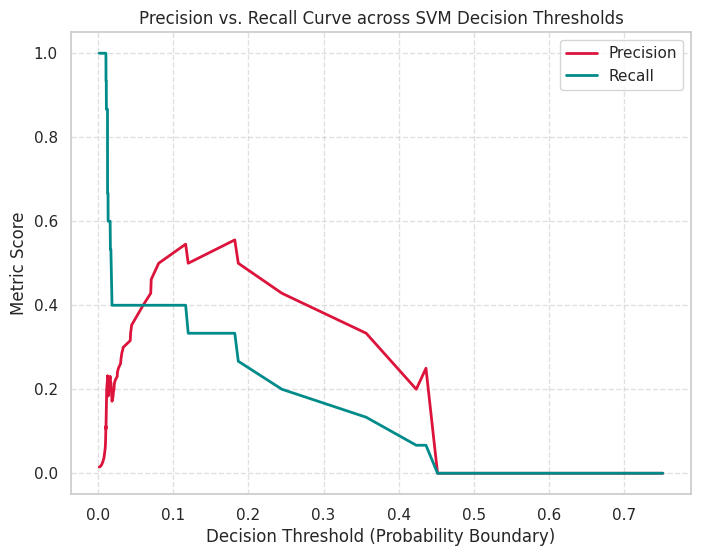

In [17]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# Compute precision-recall pairs for different thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)

plt.figure(figsize=(8, 6))
plt.plot(thresholds, precisions[:-1], label="Precision", color="crimson", lw=2)
plt.plot(thresholds, recalls[:-1], label="Recall", color="darkcyan", lw=2)

plt.xlabel("Decision Threshold (Probability Boundary)")
plt.ylabel("Metric Score")
plt.title("Precision vs. Recall Curve across SVM Decision Thresholds")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="best")
plt.show()

In [18]:
import pandas as pd
from sklearn.metrics import roc_auc_score

# Compute exact ROC-AUC score for each model
auc_records = []
for name, probs in model_probabilities.items():
    score = roc_auc_score(y_test, probs)
    auc_records.append({
        'Model': name,
        'ROC-AUC Score': round(score, 4)
    })

# Convert to a DataFrame and sort descending by AUC score
auc_table = pd.DataFrame(auc_records).sort_values(by='ROC-AUC Score', ascending=False).reset_index(drop=True)
display(auc_table)

,Model,ROC-AUC Score
0,SVM (Linear),0.9823
1,Logistic Regression,0.9817
2,Optimized SVM,0.9672
3,Decision Tree (Max Depth 4),0.9514
4,Decision Tree (Max Depth 3),0.9492
5,Random Forest,0.9488
6,k-Nearest Neighbors,0.8554
